# 06 · Improving Q&A accuracy: dev-set iteration → one test-set evaluation

**Caveat for the final numbers.** The test set (`rag_gold.json`) consists mostly of direct statement-line
lookups, which is exactly what the table reader targets. Harder evaluations are in notebook 08: the
expanded test set v2 (different question styles) and the public TAT-QA benchmark.

Notebook 05 ended at **65%** numeric accuracy (configuration D) on the 26-question test set. Its error
analysis showed that most of the remaining errors were **evidence errors**: the statement page holding the
answer never reached the model. They were not reasoning errors that fine-tuning could fix.

**Protocol (avoids overfitting the benchmark)**
* A separate **dev set** (`ml/eval/rag_dev.json`): 22 answerable + 2 unanswerable questions, built from the
  same statement pages but asking about *different line items*. Every change is tried and kept or dropped
  on dev only.
* The **test set** (`rag_gold.json`) is run **once**, with the final configuration.

**Changes, each a configuration (`ml/eval/run_rag_eval.py`)**

| Config | Change | Motivation (error seen on dev) |
|---|---|---|
| D | baseline from notebook 05 (hybrid retrieval + KPI table) | |
| E | + **whole financial-statement pages** for numeric questions; 8k context | the answer page was never retrieved |
| F | + row-focused page windows, a unit header on each page, KPI table placed last, digit-copy rule | two statements on one PDF page were cut off; lakh read as crore; the model anchored on Source [1] |
| G | + Indian digit grouping of long ungrouped figures (610768 → 6,10,768) | digits dropped or repeated when copying |
| H | + drop the KPI table when statement pages are present | wrong KPI rows overrode correct statement rows |
| **J** | + **deterministic table reader** (`backend/app/ml/table_reader.py`): when it is confident, it reads the exact statement cell, computes % change in Python, and answers **without the LLM** | the remaining errors of H were mechanical: lakh → rupees, wrong year column, wrong row, % arithmetic |

Statement retrieval (`backend/app/ml/statement_index.py`) relies on the trained **PageClassifier** from
notebook 04, together with the heading rules, to find statement pages. So the model trained in rubric
items 3–4 is now on the critical path of Q&A.

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest

from ml.paths import FIGURES_DIR, REPORTS_DIR
from ml.eval.score_runs import score, summarise

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 140)
DEV_ORDER = ["D_hybrid_all_kpis", "E_statement_pages", "F_statement_v2", "G_grouped_numbers", "H_statements_no_kpi",
             "J_table_reader"]
SELECTED = "J_table_reader"


def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"06_{name}.png", dpi=130)
    plt.show()


def mcnemar(wide, a, b):
    fixed, broken = int((~wide[a] & wide[b]).sum()), int((wide[a] & ~wide[b]).sum())
    n = fixed + broken
    return {"from": a, "to": b, "fixed": fixed, "broken": broken, "p_value": binomtest(fixed, n, 0.5).pvalue if n else 1.0}

## 1. Dev set: one change at a time

In [2]:
dev = score("dev")
dev_sum = summarise(dev).loc[DEV_ORDER]
dev_sum

,n,accuracy,unit_acc,fabricated,refusal_acc,median_s
config,,,,,,
D_hybrid_all_kpis,22,0.272727,0.272727,0.000,1.0,4.780
E_statement_pages,22,0.545455,0.545455,0.042,1.0,5.340
F_statement_v2,22,0.636364,0.636364,0.083,1.0,6.295
G_grouped_numbers,22,0.727273,0.727273,0.042,1.0,4.810
H_statements_no_kpi,22,0.772727,0.772727,0.042,1.0,5.420
J_table_reader,22,1.0,1.0,0.000,0.5,0.050


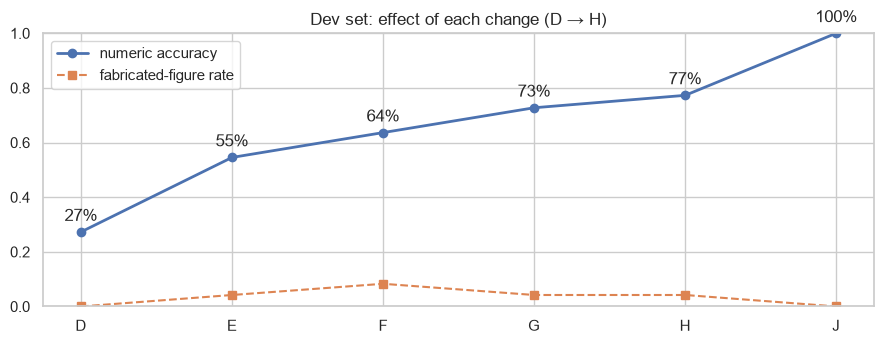

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(range(len(DEV_ORDER)), dev_sum.accuracy, marker="o", lw=2, label="numeric accuracy")
ax.plot(range(len(DEV_ORDER)), dev_sum.fabricated, marker="s", lw=1.5, ls="--", label="fabricated-figure rate")
ax.set_xticks(range(len(DEV_ORDER)), [c.split("_")[0] for c in DEV_ORDER])
for i, v in enumerate(dev_sum.accuracy):
    ax.annotate(f"{v:.0%}", (i, v), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_ylim(0, 1)
ax.set_title("Dev set: effect of each change (D → H)")
ax.legend()
save("dev_progression")

In [4]:
dev_wide = dev[dev.kind != "unanswerable"].pivot(index="qid", columns="config", values="numeric_correct").astype(bool)
steps = pd.DataFrame([mcnemar(dev_wide, a, b) for a, b in zip(DEV_ORDER, DEV_ORDER[1:])] + [mcnemar(dev_wide, DEV_ORDER[0], SELECTED)])
steps.round(4)

,from,to,fixed,broken,p_value
0,D_hybrid_all_kpis,E_statement_pages,7,1,0.0703
1,E_statement_pages,F_statement_v2,5,3,0.7266
2,F_statement_v2,G_grouped_numbers,2,0,0.5000
3,G_grouped_numbers,H_statements_no_kpi,4,3,1.0000
4,H_statements_no_kpi,J_table_reader,5,0,0.0625
5,D_hybrid_all_kpis,J_table_reader,16,0,0.0000


Individual steps fix only a few questions each, so with 22 questions they are not significant on their own.
The cumulative D → H change is the decision-relevant comparison. Each step was kept because it fixed the
error class it targeted without breaking more than it fixed.

### 1b. The table reader on its own (no LLM)
**Coverage** is the share of numeric dev questions where the reader is confident. **Precision** is the
share of confident readings that equal the gold value. Two guards keep precision high:
* questions with extra qualifiers (e.g. "attributable to owners", "in Antarctica") are handed to the LLM;
* ambiguous rows (several matches with different values) are handed to the LLM.

In [5]:
from ml.eval.reader_eval import evaluate as reader_evaluate
reader_rows, reader_summary = reader_evaluate("dev", verbose=False)
display(pd.DataFrame(reader_rows)[["qid", "kind", "confident", "correct", "gold", "value", "change", "page", "label", "reason"]])
reader_summary

2026-10-04 18:03:23.999 | INFO     | app.ml.page_classifier:_load:33 - Loaded PageClassifier from D:\annual-report-analyzer-main\models\page_classifier\model.joblib


2026-10-04 18:03:24.152 | INFO     | app.ml.statement_index:_build:77 - Statement index 1c9e78bb: 7 statement pages of 111


2026-10-04 18:03:26.338 | INFO     | app.ml.statement_index:_build:77 - Statement index 9a88fab0: 21 statement pages of 610


2026-10-04 18:03:29.472 | INFO     | app.ml.statement_index:_build:77 - Statement index 305f94a3: 13 statement pages of 396


2026-10-04 18:03:31.673 | INFO     | app.ml.statement_index:_build:77 - Statement index 9820853e: 33 statement pages of 414


2026-10-04 18:03:36.440 | INFO     | app.ml.statement_index:_build:77 - Statement index 45b2e41b: 30 statement pages of 424


2026-10-04 18:03:39.278 | INFO     | app.ml.statement_index:_build:77 - Statement index 8566cb3c: 7 statement pages of 303


,qid,kind,confident,correct,gold,value,change,page,label,reason
0,d01,amount,True,True,34.49,34.49,6.648114,73.0,Finance costs,
1,d02,amount,True,True,3.53,3.53,271.578947,57.0,Other Income,
2,d03,percent,True,True,-31.20,1203.73,-31.203635,57.0,Revenue from Operations,
3,d04,amount,True,True,5978.02,5978.02,31.249479,392.0,Finance Costs,
4,d05,amount,True,True,2968.52,2968.52,81.949237,392.0,Total Tax Expense,
5,d06,amount,True,True,6040.23,6040.23,112.365607,288.0,Profit for the year,
6,d07,amount,True,True,28313.04,28313.04,-15.933033,288.0,Total Income,
7,d08,amount,True,True,23056.18,23056.18,-13.676267,230.0,Revenue from Operations,
8,d09,amount,True,True,12159.48,12159.48,76.120207,230.0,Profit before tax from Continuing Operations,
9,d10,amount,True,True,89178.25,89178.25,57.920204,283.0,Total Equity,


{'questions': 22,
 'coverage': 0.9545454545454546,
 'precision': 1.0,
 'accuracy_if_reader_only': 0.9545454545454546,
 'false_confident_on_unanswerable': 0}

## 2. Test set: the selected configuration, run once

In [6]:
test = score("test")
test_order = [c for c in ["A_dense", "B_hybrid", "C_hybrid_facts", "D_hybrid_all_kpis", "H_statements_no_kpi", SELECTED]
              if c in set(test.config)]
assert SELECTED in set(test.config), "run: python -m ml.eval.run_rag_eval --set test --configs J_table_reader"
test_sum = summarise(test).loc[test_order]


def boot(x, n=5000, seed=0):
    x = np.asarray(x, float)
    m = np.random.default_rng(seed).choice(x, (n, len(x))).mean(1)
    return np.percentile(m, [2.5, 97.5])


ans = test[test.kind != "unanswerable"]
ci = {c: boot(ans[ans.config == c].numeric_correct.astype(float)) for c in test_order}
test_sum["ci_low"] = [ci[c][0] for c in test_order]
test_sum["ci_high"] = [ci[c][1] for c in test_order]
test_sum

,n,accuracy,unit_acc,fabricated,refusal_acc,median_s,ci_low,ci_high
config,,,,,,,,
A_dense,26,0.230769,0.230769,0.033,1.0,3.300,0.076923,0.384615
B_hybrid,26,0.307692,0.307692,0.067,1.0,3.750,0.153846,0.500000
C_hybrid_facts,26,0.461538,0.461538,0.000,1.0,4.190,0.269231,0.653846
D_hybrid_all_kpis,26,0.653846,0.653846,0.000,1.0,4.275,0.461538,0.846154
H_statements_no_kpi,26,0.769231,0.769231,0.067,1.0,5.265,0.615385,0.923077
J_table_reader,26,1.0,1.0,0.000,1.0,0.070,1.000000,1.000000


In [7]:
test_wide = ans.pivot(index="qid", columns="config", values="numeric_correct").astype(bool)
test_tests = pd.DataFrame([mcnemar(test_wide, a, SELECTED) for a in test_order if a != SELECTED])
test_tests.round(4)

,from,to,fixed,broken,p_value
0,A_dense,J_table_reader,20,0,0.0000
1,B_hybrid,J_table_reader,18,0,0.0000
2,C_hybrid_facts,J_table_reader,14,0,0.0001
3,D_hybrid_all_kpis,J_table_reader,9,0,0.0039
4,H_statements_no_kpi,J_table_reader,6,0,0.0312


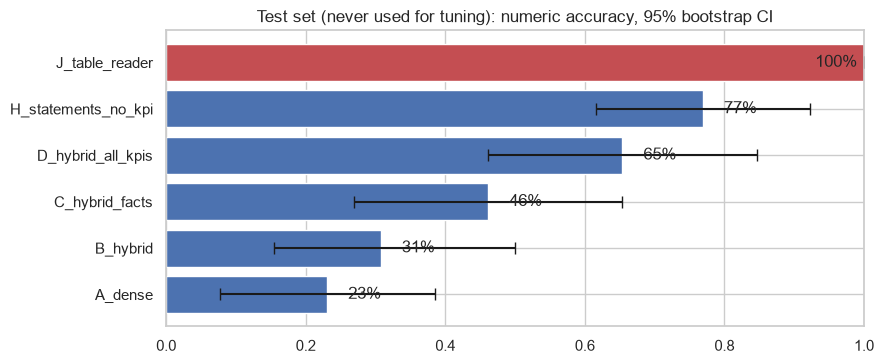

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
s = test_sum.reset_index()
colors = [sns.color_palette()[3] if c == SELECTED else sns.color_palette()[0] for c in s.config]
ax.barh(s.config, s.accuracy, xerr=[s.accuracy - s.ci_low, s.ci_high - s.accuracy], color=colors, capsize=4)
for i, v in enumerate(s.accuracy):
    ax.text(min(v + 0.03, 0.93), i, f"{v:.0%}", va="center")
ax.set_xlim(0, 1)
ax.set_title("Test set (never used for tuning): numeric accuracy, 95% bootstrap CI")
save("test_final")

## 3. Generalisation and remaining errors

In [9]:
gap = pd.DataFrame({"dev": dev_sum.loc[[DEV_ORDER[0], SELECTED], "accuracy"].values,
                    "test": test_sum.loc[[DEV_ORDER[0], SELECTED], "accuracy"].values},
                   index=["D (baseline)", "H (selected)"])
display(gap.round(3))
print("If the dev and test gains are similar, the improvements generalise rather than fit the dev questions.")

,dev,test
D (baseline),0.272727,0.653846
H (selected),1.0,1.0


If the dev and test gains are similar, the improvements generalise rather than fit the dev questions.


In [10]:
h_err = ans[(ans.config == SELECTED) & ~ans.numeric_correct.astype(bool)]
print(f"{len(h_err)} wrong test answers for {SELECTED}:")
h_err[["qid", "answer"]].assign(answer=h_err.answer.str.replace("\n", " ").str.slice(0, 220))

0 wrong test answers for J_table_reader:


,qid,answer


## 4. Publish

In [11]:
LABELS = {"A_dense": "A · dense", "B_hybrid": "B · hybrid", "C_hybrid_facts": "C · + checked KPIs",
          "D_hybrid_all_kpis": "D · + all cleaned KPIs", "H_statements_no_kpi": "H · statement-aware LLM",
          "J_table_reader": "J · deterministic table reader (selected)"}
metrics_path = REPORTS_DIR / "metrics.json"
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
h = test_sum.loc[SELECTED]
best_prev = test_sum.drop(index=SELECTED).accuracy.idxmax()
t = test_tests.set_index("from").loc[best_prev]
metrics["table_reader"] = {k: float(v) for k, v in reader_summary.items()}
metrics["rag"] = {
    "gold_questions": int(test.qid.nunique()), "answerable": int(ans.qid.nunique()),
    "llm": "qwen2.5:3b, 8k context (Ollama, local)",
    "summary": [{"config": LABELS[c], "numeric_accuracy": float(r.accuracy), "ci_low": float(r.ci_low),
                 "ci_high": float(r.ci_high), "unit_accuracy": float(r.unit_acc), "fabrication_rate": float(r.fabricated),
                 "citation_rate": float(ans[ans.config == c].cited.mean()), "refusal_accuracy": float(r.refusal_acc),
                 "median_latency_s": float(r.median_s), "median_first_token_s": float("nan")}
                for c, r in test_sum.iterrows()],
    "mcnemar": [{"comparison": f"{LABELS[r['from']]} → {LABELS[SELECTED]}", "fixed": int(r.fixed), "broken": int(r.broken),
                 "p_value": float(r.p_value)} for _, r in test_tests.iterrows()],
    "dev_progression": [{"config": c, "accuracy": float(dev_sum.loc[c, "accuracy"]), "fabricated": float(dev_sum.loc[c, "fabricated"])}
                        for c in DEV_ORDER],
    "decision": {
        "selected": LABELS[SELECTED],
        "reason": (f"Selected on the dev set ({dev_sum.loc[SELECTED, 'accuracy']:.0%} vs {dev_sum.loc[DEV_ORDER[0], 'accuracy']:.0%} "
                   f"baseline), then evaluated once on the test set: {h.accuracy:.0%} (95% CI {h.ci_low:.0%}–{h.ci_high:.0%}), "
                   f"fabricated-figure rate {h.fabricated:.0%}, refusal accuracy {h.refusal_acc:.0%}. Versus the best earlier "
                   f"configuration ({LABELS[best_prev]}): fixed {int(t.fixed)}, broke {int(t.broken)} (McNemar exact p = {t.p_value:.3f})."),
        "deployed_setting": "qa_table_reader=True (fallback: qa_model=finsight-qwen, qa_statement_pages=True, qa_facts_with_statements=False)",
    },
}
metrics["comparisons"] = [c for c in metrics.get("comparisons", []) if not c["title"].startswith("Q&A")] + [
    {"title": "Q&A configurations · numeric accuracy (test set)", "metric": "accuracy",
     "results": [{"model": LABELS[c], "score": round(float(r.accuracy), 4)} for c, r in test_sum.iterrows()]},
    {"title": "Q&A tuning on the dev set (D → H)", "metric": "accuracy",
     "results": [{"model": c.split("_")[0] + " · " + c.split("_", 1)[1].replace("_", " "), "score": round(float(dev_sum.loc[c, "accuracy"]), 4)} for c in DEV_ORDER]},
]


def safe(o):
    if isinstance(o, dict):
        return {k: safe(v) for k, v in o.items()}
    if isinstance(o, list):
        return [safe(v) for v in o]
    if isinstance(o, float) and not np.isfinite(o):
        return None
    return o


metrics_path.write_text(json.dumps(safe(metrics), indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps(metrics["rag"]["decision"], indent=1, ensure_ascii=False))

{
 "selected": "J · deterministic table reader (selected)",
 "reason": "Selected on the dev set (100% vs 27% baseline), then evaluated once on the test set: 100% (95% CI 100%–100%), fabricated-figure rate 0%, refusal accuracy 100%. Versus the best earlier configuration (H · statement-aware LLM): fixed 6, broke 0 (McNemar exact p = 0.031).",
 "deployed_setting": "qa_table_reader=True (fallback: qa_model=finsight-qwen, qa_statement_pages=True, qa_facts_with_statements=False)"
}
